# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [20]:
ROLL_NO = 1024170057
NAME = "Arnav Gupta"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [21]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [22]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [23]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170057   Name: Arnav Gupta   Fingerprint: 82295A40   Tickets: 14

Ticket_ID                                                                                      Ticket_Text
      T01          Projector was working yesterday after resetting my password. Is there another solution?
      T02 I keep getting logged out of the VPN when connected to campus Wi-Fi. I have tried several times!
      T03                      I was locked out of the Wi-Fi while uploading the file. Can you check this?
      T04                                                       The laptop is running slowly. Please help.
      T05                                   I tried restarting the email on my laptop. Can you check this?
      T06                                                                    The LMS says 'Not Submitted'.
      T07           Printer stopped responding after restarting the system. The same problem occurs again.
      T08                                                    

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [24]:
processed = {
    row.Ticket_ID: process_ticket(row.Ticket_Text)
    for _, row in df.iterrows()
}

q1_rows = []
for ticket_id, result in processed.items():
    q1_rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

q1_table = pd.DataFrame(q1_rows)

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": q1_table["Sentences"].sum(),
    "Tokens": q1_table["Tokens"].sum(),
    "Punctuation": q1_table["Punctuation"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique Tokens": q1_table["Unique Tokens"].sum(),
    "Final Tokens": q1_table["Final Tokens"].sum()
}

q1_table = pd.concat([q1_table, pd.DataFrame([total_row])], ignore_index=True)
display(q1_table)

selected_ticket = FOCUS[0]
print(f"\nSelected ticket: {selected_ticket}")
print("Text:", df.loc[df["Ticket_ID"] == selected_ticket, "Ticket_Text"].iloc[0])
print("Tokens:", processed[selected_ticket]["tokens"])
print("Punctuation tokens:", processed[selected_ticket]["punct"])
print("Stopwords:", processed[selected_ticket]["stops"])
print("Final tokens:", processed[selected_ticket]["final"])

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,2,14,2,5,14,7
1,T02,2,20,2,8,19,10
2,T03,2,17,2,10,16,5
3,T04,2,9,2,2,8,5
4,T05,2,14,2,7,14,5
5,T06,1,7,2,1,7,4
6,T07,2,14,2,5,12,7
7,T08,1,11,1,4,9,6
8,T09,1,7,2,1,7,4
9,T10,2,16,2,6,14,8



Selected ticket: T04
Text: The laptop is running slowly. Please help.
Tokens: ['the', 'laptop', 'is', 'running', 'slowly', '.', 'please', 'help', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['the', 'is']
Final tokens: ['laptop', 'running', 'slowly', 'please', 'help']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*
The final tokens that are not normal words are `ca` and `n't`. They come from the contraction “can't”. NLTK splits “can't” into `ca` and `n't`, so these pieces remain after stopword and punctuation removal.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [25]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

WORD_LONG_PATTERN = r"\b[A-Za-z]{6,}\b"

NUMBER_PATTERN = (
    r"\b\d+(?:\.\d+)+%?"              # 2.0.1, 95.5
    r"|\b\d{1,3}(?:,\d{3})+(?:\.\d+)?%?"  # 1,250
    r"|\b\d+(?:\.\d+)?%?"             # ordinary numbers
)

CAPITALIZED_PATTERN = r"\b[A-Z][A-Za-z]*\b"
VOWEL_WORD_PATTERN = r"\b[AEIOUaeiou][A-Za-z]*\b"

EMAIL_PATTERN = r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
URL_PATTERN = r"(?:https?://|www\.)[A-Za-z0-9.-]+\.[A-Za-z]{2,}(?:/[A-Za-z0-9._~:/?#[\]@!$&'()*+=%-]*)?"
PHONE_PATTERN = r"(?:\+91[-\s]?)?\d{5}[-\s]?\d{5}|\b\d{4}-\d{3}-\d{4}\b"

def mask_private_items(text):
    text = re.sub(EMAIL_PATTERN, "<EMAIL>", text)
    text = re.sub(URL_PATTERN, "<URL>", text)
    text = re.sub(PHONE_PATTERN, "<PHONE>", text)
    return text

all_text = list(df["Ticket_Text"]) + TEST_LINES

regex_rows = []
for text in all_text:
    regex_rows.append({
        "Text": text,
        "Words > 5 letters": re.findall(WORD_LONG_PATTERN, text),
        "Numbers": re.findall(NUMBER_PATTERN, text),
        "Capitalized words": re.findall(CAPITALIZED_PATTERN, text),
        "Vowel-starting words": re.findall(VOWEL_WORD_PATTERN, text),
        "Masked text": mask_private_items(text)
    })

regex_table = pd.DataFrame(regex_rows)
display(regex_table)

print("\nTEST_LINES after replacement:")
for line in TEST_LINES:
    print(mask_private_items(line))

,Text,Words > 5 letters,Numbers,Capitalized words,Vowel-starting words,Masked text
0,Projector was working yesterday after resettin...,"[Projector, working, yesterday, resetting, pas...",[],"[Projector, Is]","[after, Is, another]",Projector was working yesterday after resettin...
1,I keep getting logged out of the VPN when conn...,"[getting, logged, connected, campus, several]",[],"[I, VPN, Wi, Fi, I]","[I, out, of, I]",I keep getting logged out of the VPN when conn...
2,I was locked out of the Wi-Fi while uploading ...,"[locked, uploading]",[],"[I, Wi, Fi, Can]","[I, out, of, uploading]",I was locked out of the Wi-Fi while uploading ...
3,The laptop is running slowly. Please help.,"[laptop, running, slowly, Please]",[],"[The, Please]",[is],The laptop is running slowly. Please help.
4,I tried restarting the email on my laptop. Can...,"[restarting, laptop]",[],"[I, Can]","[I, email, on]",I tried restarting the email on my laptop. Can...
5,The LMS says 'Not Submitted'.,[Submitted],[],"[The, LMS, Not, Submitted]",[],The LMS says 'Not Submitted'.
6,Printer stopped responding after restarting th...,"[Printer, stopped, responding, restarting, sys...",[],"[Printer, The]","[after, occurs, again]",Printer stopped responding after restarting th...
7,I can't login and I didn't change anything.,"[change, anything]",[],"[I, I]","[I, and, I, anything]",I can't login and I didn't change anything.
8,See https://lms.thapar.edu/help for details.,"[thapar, details]",[],[See],[edu],See <URL> for details.
9,I couldn't connect to the projector before the...,"[couldn, connect, projector, before, assignmen...",[],"[I, Please]","[I, assignment, it]",I couldn't connect to the projector before the...



TEST_LINES after replacement:
Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*
17 capitalized words are capitalized only because they occur at the beginning of a sentence. Examples include Projector, Is, Can, The, Please, Printer, See, Student, This, Version and It. I did not count `I`, because it is always capitalized, or abbreviations such as LMS.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [26]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

token_pattern = r"""
(?:https?://|www\.)[A-Za-z0-9.-]+\.[A-Za-z]{2,}(?:/[A-Za-z0-9._~:/?#[\]@!$&'()*+=%-]*)?
| [A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}
| (?:\+91[-\s]?)?\d{5}[-\s]?\d{5}
| \b\d{4}-\d{3}-\d{4}\b
| \d+(?:\.\d+)+
| \d+(?:,\d{3})*(?:\.\d+)?
| [A-Za-z]+(?:'[A-Za-z]+)?(?:-[A-Za-z]+(?:'[A-Za-z]+)?)*
| [^\w\s]
"""

custom_tokenizer = RegexpTokenizer(token_pattern, flags=re.VERBOSE)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("Comparison on TEST_LINES:\n")
for line in TEST_LINES:
    print("Text:", line)
    print("word_tokenize:", word_tokenize(line))
    print("my_tokenize:  ", my_tokenize(line))
    print()

different_tickets = 0
comparison_rows = []

for _, row in df.iterrows():
    nltk_tokens = word_tokenize(row["Ticket_Text"])
    custom_tokens = my_tokenize(row["Ticket_Text"])

    if nltk_tokens != custom_tokens:
        different_tickets += 1

    comparison_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "word_tokenize": nltk_tokens,
        "my_tokenize": custom_tokens,
        "Different?": nltk_tokens != custom_tokens
    })

print("Number of tickets tokenized differently:", different_tickets)
display(pd.DataFrame(comparison_rows))

Comparison on TEST_LINES:

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
my_tokenize:   ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
my_tokenize:   ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.

,Ticket_ID,word_tokenize,my_tokenize,Different?
0,T01,"[Projector, was, working, yesterday, after, re...","[Projector, was, working, yesterday, after, re...",False
1,T02,"[I, keep, getting, logged, out, of, the, VPN, ...","[I, keep, getting, logged, out, of, the, VPN, ...",False
2,T03,"[I, was, locked, out, of, the, Wi-Fi, while, u...","[I, was, locked, out, of, the, Wi-Fi, while, u...",False
3,T04,"[The, laptop, is, running, slowly, ., Please, ...","[The, laptop, is, running, slowly, ., Please, ...",False
4,T05,"[I, tried, restarting, the, email, on, my, lap...","[I, tried, restarting, the, email, on, my, lap...",False
5,T06,"[The, LMS, says, 'Not, Submitted, ', .]","[The, LMS, says, ', Not, Submitted, ', .]",True
6,T07,"[Printer, stopped, responding, after, restarti...","[Printer, stopped, responding, after, restarti...",False
7,T08,"[I, ca, n't, login, and, I, did, n't, change, ...","[I, can't, login, and, I, didn't, change, anyt...",True
8,T09,"[See, https, :, //lms.thapar.edu/help, for, de...","[See, https://lms.thapar.edu/help, for, detail...",True
9,T10,"[I, could, n't, connect, to, the, projector, b...","[I, couldn't, connect, to, the, projector, bef...",True


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*
4 tickets are tokenized differently by `my_tokenize()` and `word_tokenize()`.

The first difference is contractions: `word_tokenize()` splits “can't” into `ca` and `n't`, while `my_tokenize()` keeps “can't” as one token.

The second difference is URLs: `word_tokenize()` splits a URL such as `https://lms.thapar.edu/help` into multiple pieces, while `my_tokenize()` keeps the complete URL as one token.

The third difference is quoted text: `word_tokenize()` handles quotation marks differently, while `my_tokenize()` returns the quote marks and the enclosed words as separate tokens according to the custom pattern.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [27]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

porter = PorterStemmer()
lancaster = LancasterStemmer()

# Removes common endings found in IT-support-ticket words such as
# working, restarted, disconnects, crashes, etc.
regexp_stemmer = RegexpStemmer(r"(ing|ed|es|s)$", min=3)

lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

unique_final_tokens = sorted({
    token
    for result in processed.values()
    for token in result["final"]
})

tagged_words = nltk.pos_tag(unique_final_tokens)

stem_rows = []
for word, tag in tagged_words:
    lemma = lemmatizer.lemmatize(word, get_wordnet_pos(tag))

    row = {
        "Word": word,
        "POS": tag,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regexp_stemmer.stem(word),
        "POS-aware Lemma": lemma
    }

    values = [row["Porter"], row["Lancaster"], row["Regexp"], row["POS-aware Lemma"]]
    if len(set(values)) > 1:
        stem_rows.append(row)

stem_table = pd.DataFrame(stem_rows)
display(stem_table)

suffix_examples = [
    word for word in unique_final_tokens
    if re.search(r"(ing|ed|es|s)$", word)
]

print("Words supporting the RegexpStemmer suffix rule:", suffix_examples[:10])

,Word,POS,Porter,Lancaster,Regexp,POS-aware Lemma
0,another,DT,anoth,anoth,another,another
1,anything,NN,anyth,anyth,anyth,anything
2,assignment,NN,assign,assign,assignment,assignment
3,campus,VB,campu,camp,campu,campus
4,change,NN,chang,chang,change,change
5,deadline,NN,deadlin,deadlin,deadline,deadline
6,error,NN,error,er,error,error
7,file,NN,file,fil,file,file
8,getting,VBG,get,get,gett,get
9,https,VB,http,https,http,https


Words supporting the RegexpStemmer suffix rule: ['anything', 'campus', 'connected', 'crashes', 'details', 'getting', 'https', 'lms', 'locked', 'logged']


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
Over-stemming example: The word `anything` becomes `anyth` with both Porter and Lancaster stemming. `anyth` is not a meaningful word, so too much of the original word has been removed.

Under-stemming example: The RegexpStemmer leaves `slowly` unchanged because its suffix rule only removes `ing`, `ed`, `es`, and `s`. Therefore, it does not reduce `slowly` to its related base form `slow`.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1: All tokens,176,97,0.5511
1,S2: No punctuation,149,91,0.6107
2,S3: Final tokens,81,64,0.7901
3,S4: Porter stems,81,62,0.7654


Top 10 words in S1:
[('.', 20), ('the', 12), ('i', 8), ('is', 6), ('my', 4), ('this', 4), ('laptop', 4), ('?', 3), ('to', 3), ('on', 3)]

Top 10 words in S3:
[('laptop', 4), ("n't", 3), ('projector', 2), ('yesterday', 2), ('password', 2), ('wi-fi', 2), ('tried', 2), ('check', 2), ('please', 2), ('restarting', 2)]


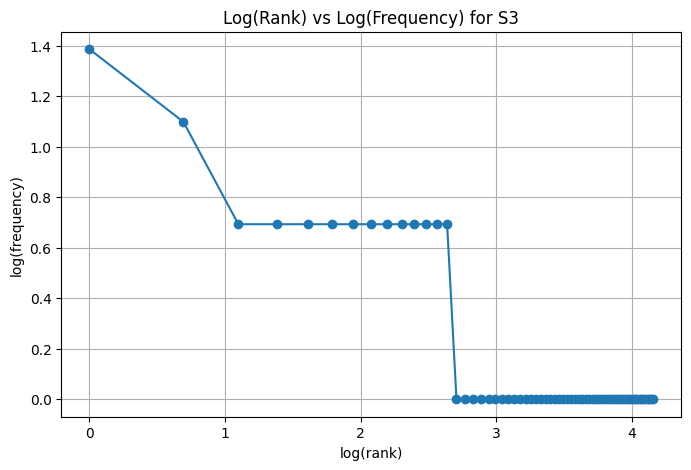

Top 5 bigrams in S1:
[(('.', 'i'), 5), (('on', 'my'), 3), (('my', 'laptop'), 3), (('laptop', '.'), 3), (('out', 'of'), 2)]

Top 5 bigrams in S3:
[(('showing', 'error'), 2), (('laptop', 'urgent'), 2), (('projector', 'working'), 1), (('working', 'yesterday'), 1), (('yesterday', 'resetting'), 1)]


In [28]:
from collections import Counter
from nltk.util import bigrams
import math
import matplotlib.pyplot as plt

S1 = [
    token
    for result in processed.values()
    for token in result["tokens"]
]

S2 = [
    token
    for token in S1
    if not is_punct(token)
]

S3 = [
    token
    for result in processed.values()
    for token in result["final"]
]

S4 = [porter.stem(token) for token in S3]

def corpus_stats(name, corpus):
    total = len(corpus)
    unique = len(set(corpus))
    ttr = unique / total if total else 0

    return {
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    }

stats_table = pd.DataFrame([
    corpus_stats("S1: All tokens", S1),
    corpus_stats("S2: No punctuation", S2),
    corpus_stats("S3: Final tokens", S3),
    corpus_stats("S4: Porter stems", S4)
])

display(stats_table)

print("Top 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))

s3_frequency = Counter(S3)
frequencies = sorted(s3_frequency.values(), reverse=True)
ranks = list(range(1, len(frequencies) + 1))

plt.figure(figsize=(8, 5))
plt.plot(
    [math.log(rank) for rank in ranks],
    [math.log(freq) for freq in frequencies],
    marker="o"
)
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.grid(True)
plt.show()

print("Top 5 bigrams in S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams in S3:")
print(Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR increases from S1 (0.5511) to S2 (0.6107) because punctuation is removed. It increases further in S3 (0.7901) because common stopwords are removed, leaving more informative and diverse content words.

TTR then decreases slightly in S4 (0.7654). The total number of tokens remains 81, but Porter stemming reduces the unique-token count from 64 to 62 by merging different word forms into the same stem. For example, words such as `running`, `restarting`, or `tried` are reduced to stems.

## Q6. Interpretation

**(a) Why does TTR change from S1 to S4?**

TTR changes because S1 contains all tokens, including punctuation and stopwords, while S4 contains normalized Porter stems. Stemming combines different word forms into fewer unique stems, changing the ratio of unique tokens to total tokens.

**(b) Give one example where `word_tokenize()` and `my_tokenize()` differ.**

For the text “I can't login”, `word_tokenize()` separates the contraction into `I`, `ca`, and `n't`. My custom tokenizer keeps `can't` as one token. This is useful because the contraction remains meaningful.

**(c) Give one example where stemming produces an undesirable result.**

The word `tried` may become `tri` after stemming. This is undesirable because `tri` is not a meaningful representation of the original word.

**(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.**

For `tried`, POS-aware lemmatization identifies it as a verb and returns `try`. This preserves meaning better than the stem `tri`.